# EDA — Dataset Ampara Contrastive Learning

Análisis exploratorio de `questions_with_positive_context.jsonl` generado con el pipeline LLM+BM25.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

DATASET = Path("data/output/legal_questions_dataset/questions_with_positive_context.jsonl")

records = [json.loads(l) for l in DATASET.open(encoding="utf-8")]
df = pd.json_normalize(records)

df_pos_src = df.explode("positive_source_types").reset_index(drop=True)
df_neg_src = df.explode("negative_source_types").reset_index(drop=True)
df_scores  = df.explode("neg_bm25_scores").reset_index(drop=True)
df_scores["neg_bm25_scores"] = df_scores["neg_bm25_scores"].astype(float)

print(f"Registros: {len(df)}")
print(f"Columnas:  {len(df.columns)}")
print(f"Casos únicos: {df['case_id'].nunique()}")

Registros: 900
Columnas:  37
Casos únicos: 178


## 1. Visión general

In [ ]:
nulos = df.isnull().sum()
print(nulos[nulos > 0].to_string() if nulos.any() else "Sin valores nulos")

# Estadísticas de columnas numéricas clave
df[["query_length", "positive_context_count", "negative_count",
    "unresolved_count", "confidence"]].describe().round(2)

jurisprudence_match_info.matched_chunk_ids    28
source_trace.title                            18
source_trace.resolution_reference_raw         28


,query_length,positive_context_count,negative_count,unresolved_count,confidence
count,900.00,900.00,900.0,900.00,900.00
mean,83.60,1.45,10.0,0.04,0.87
std,18.81,0.61,0.0,0.20,0.07
min,45.00,1.00,10.0,0.00,0.30
25%,69.00,1.00,10.0,0.00,0.80
50%,81.00,1.00,10.0,0.00,0.85
75%,95.00,2.00,10.0,0.00,0.90
max,151.00,4.00,10.0,1.00,0.95


count    178.00
mean       5.06
std        1.56
min        1.00
25%        5.00
50%        6.00
75%        6.00
max        7.00
dtype: float64


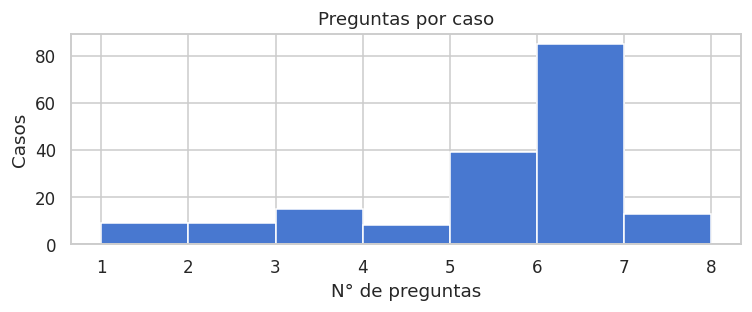

In [ ]:
per_case = df.groupby("case_id").size()
print(per_case.describe().round(2))

fig, ax = plt.subplots(figsize=(7, 3))
per_case.hist(bins=range(1, per_case.max() + 2), edgecolor="white", ax=ax)
ax.set(title="Preguntas por caso", xlabel="N° de preguntas", ylabel="Casos")
plt.tight_layout()
plt.show()

## 2. Distribución de tópicos y barreras

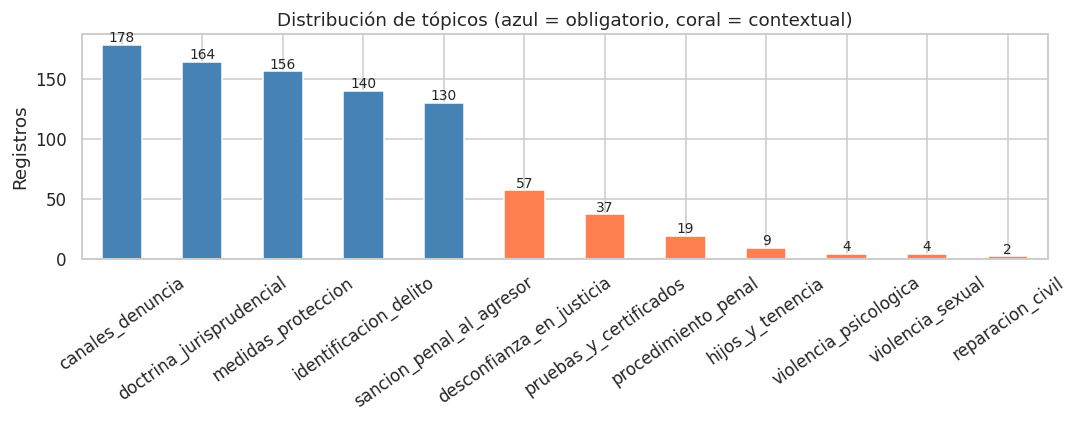

In [ ]:
MANDATORY = {"identificacion_delito", "canales_denuncia", "medidas_proteccion",
             "sancion_penal_al_agresor", "doctrina_jurisprudencial"}

topic_counts = df["topic"].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["steelblue" if t in MANDATORY else "coral" for t in topic_counts.index]
topic_counts.plot(kind="bar", ax=ax, color=colors, edgecolor="white")
ax.set(title="Distribución de tópicos (azul = obligatorio, coral = contextual)",
       xlabel="", ylabel="Registros")
ax.tick_params(axis="x", rotation=35)

# Etiquetas de valor
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

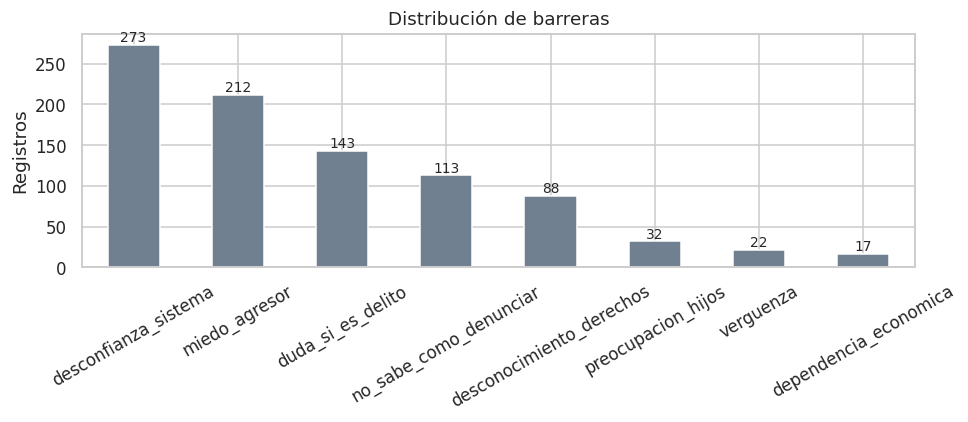

In [ ]:
barrier_counts = df["barrier"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
barrier_counts.plot(kind="bar", ax=ax, color="slategray", edgecolor="white")
ax.set(title="Distribución de barreras", xlabel="", ylabel="Registros")
ax.tick_params(axis="x", rotation=30)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Calidad de las preguntas

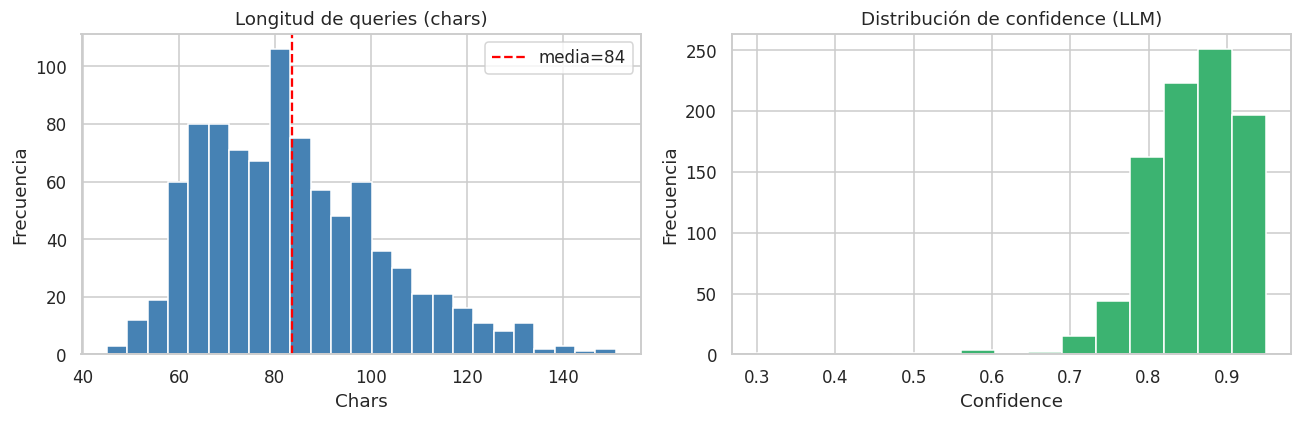

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Longitud de queries
df["query_length"].hist(bins=25, edgecolor="white", ax=axes[0], color="steelblue")
axes[0].set(title="Longitud de queries (chars)", xlabel="Chars", ylabel="Frecuencia")
axes[0].axvline(df["query_length"].mean(), color="red", linestyle="--", label=f"media={df['query_length'].mean():.0f}")
axes[0].legend()

# Confianza
df["confidence"].hist(bins=15, edgecolor="white", ax=axes[1], color="mediumseagreen")
axes[1].set(title="Distribución de confidence (LLM)", xlabel="Confidence", ylabel="Frecuencia")

plt.tight_layout()
plt.show()

/tmp/ipykernel_8694/2088700156.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="topic", y="confidence", order=order, ax=ax, palette="Blues")


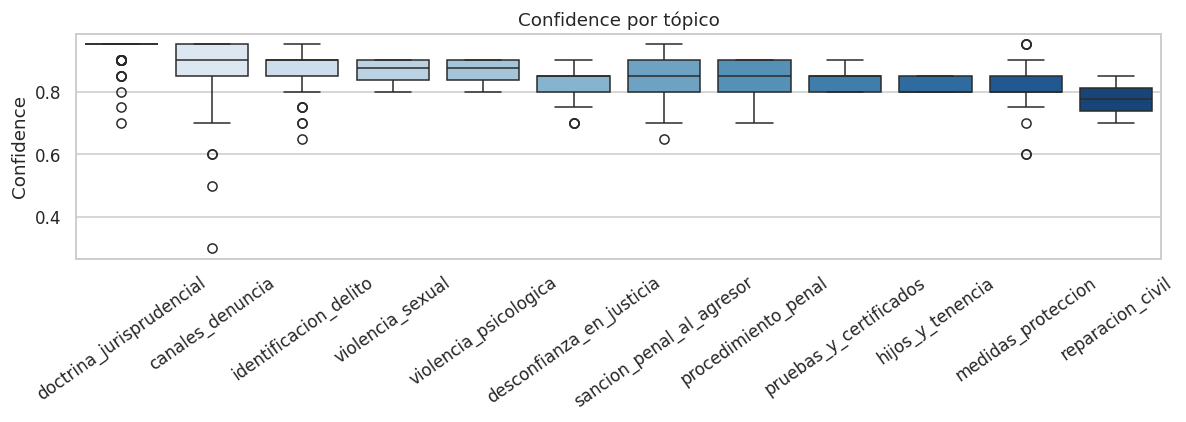


Registros con confidence < 0.75: 23


,case_id,topic,barrier,confidence,query
36,jp_00051_e0009,desconfianza_en_justicia,desconfianza_sistema,0.70,¿Aunque el Estado diga que solo pasó algo en u...
37,jp_00051_e0009,canales_denuncia,desconfianza_sistema,0.60,¿Dónde puedo pedir ayuda si no confío en la po...
38,jp_00051_e0009,identificacion_delito,duda_si_es_delito,0.65,¿Me van a creer si digo que me hicieron daño a...
39,jp_00051_e0009,desconfianza_en_justicia,desconfianza_sistema,0.70,¿Puedo pedir que publiquen lo que me pasó aunq...
41,jp_00051_e0009,reparacion_civil,desconfianza_sistema,0.70,¿Aunque me hayan negado información sobre lo q...
47,jp_00051_e0014,sancion_penal_al_agresor,desconfianza_sistema,0.70,¿Qué le puede pasar al responsable si lo denun...
131,jp_00091_e0011,desconfianza_en_justicia,dependencia_economica,0.70,¿Me van a ayudar aunque no tenga dinero para l...
198,jp_00118_e0087,canales_denuncia,verguenza,0.70,¿Dónde puedo denunciar si me da vergüenza ir a...
403,jp_00138_e0095,canales_denuncia,no_sabe_como_denunciar,0.60,¿Dónde puedo denunciar si la policía me agredi...
404,jp_00138_e0096,canales_denuncia,miedo_agresor,0.50,¿Dónde puedo pedir ayuda si tengo miedo de den...


In [ ]:
# Confidence por tópico
fig, ax = plt.subplots(figsize=(11, 4))
order = df.groupby("topic")["confidence"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="topic", y="confidence", order=order, ax=ax, palette="Blues")
ax.set(title="Confidence por tópico", xlabel="", ylabel="Confidence")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# Registros con baja confianza
bajos = df[df["confidence"] < 0.75][["case_id", "topic", "barrier", "confidence", "query"]]
print(f"\nRegistros con confidence < 0.75: {len(bajos)}")
bajos

## 4. Análisis de positivos

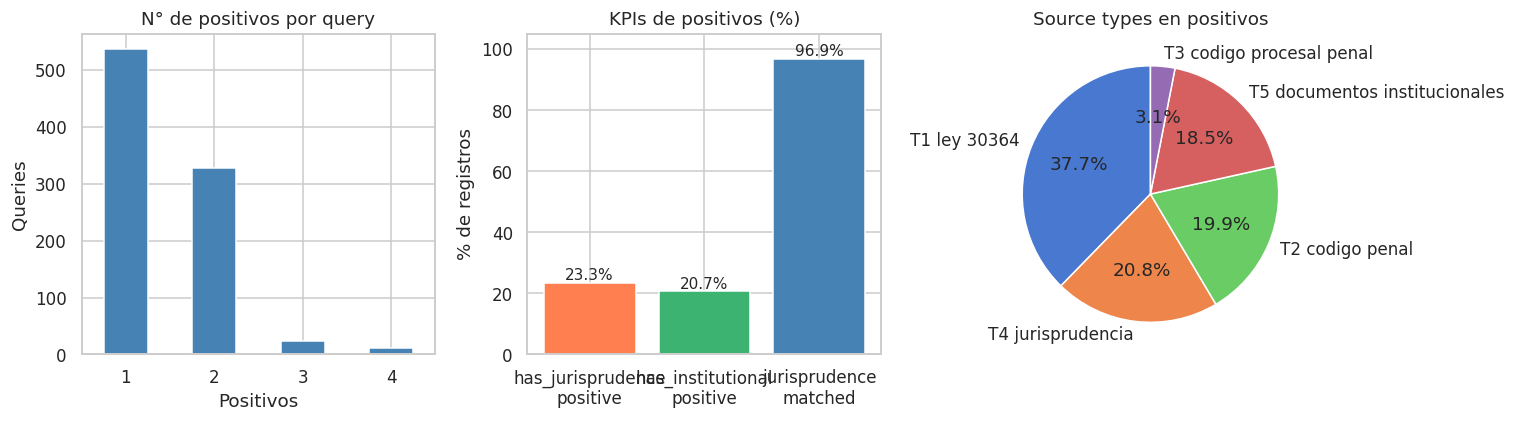

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Distribución positive_context_count
df["positive_context_count"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set(title="N° de positivos por query", xlabel="Positivos", ylabel="Queries")
axes[0].tick_params(axis="x", rotation=0)

# KPIs booleanos
kpis = {
    "has_jurisprudence\npositive": df["has_jurisprudence_positive"].mean() * 100,
    "has_institutional\npositive": df["has_institutional_positive"].mean() * 100,
    "jurisprudence\nmatched": df["jurisprudence_matched"].mean() * 100,
}
axes[1].bar(kpis.keys(), kpis.values(), color=["coral", "mediumseagreen", "steelblue"], edgecolor="white")
axes[1].set(title="KPIs de positivos (%)", ylim=(0, 105), ylabel="% de registros")
for i, (k, v) in enumerate(kpis.items()):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)

# Source types de positivos
src_counts = df_pos_src["positive_source_types"].value_counts()
src_short = src_counts.rename(index=lambda x: x.replace("tipo_0", "T").replace("_", " ") if isinstance(x, str) else x)
src_short.plot(kind="pie", ax=axes[2], autopct="%1.1f%%", startangle=90,
               colors=sns.color_palette("muted", len(src_counts)))
axes[2].set(title="Source types en positivos", ylabel="")

plt.tight_layout()
plt.show()

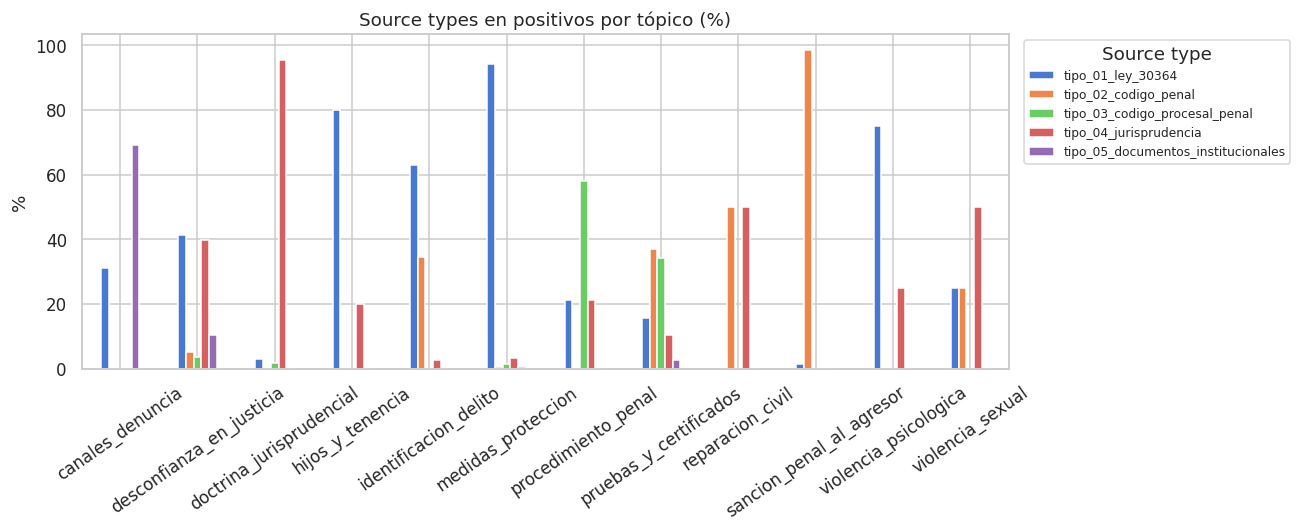

In [ ]:
# Source types de positivos por tópico
cross = pd.crosstab(df_pos_src["topic"], df_pos_src["positive_source_types"])
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
cross_pct.plot(kind="bar", ax=ax, edgecolor="white")
ax.set(title="Source types en positivos por tópico (%)", xlabel="", ylabel="%")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Source type", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Heatmap tópico × barrera

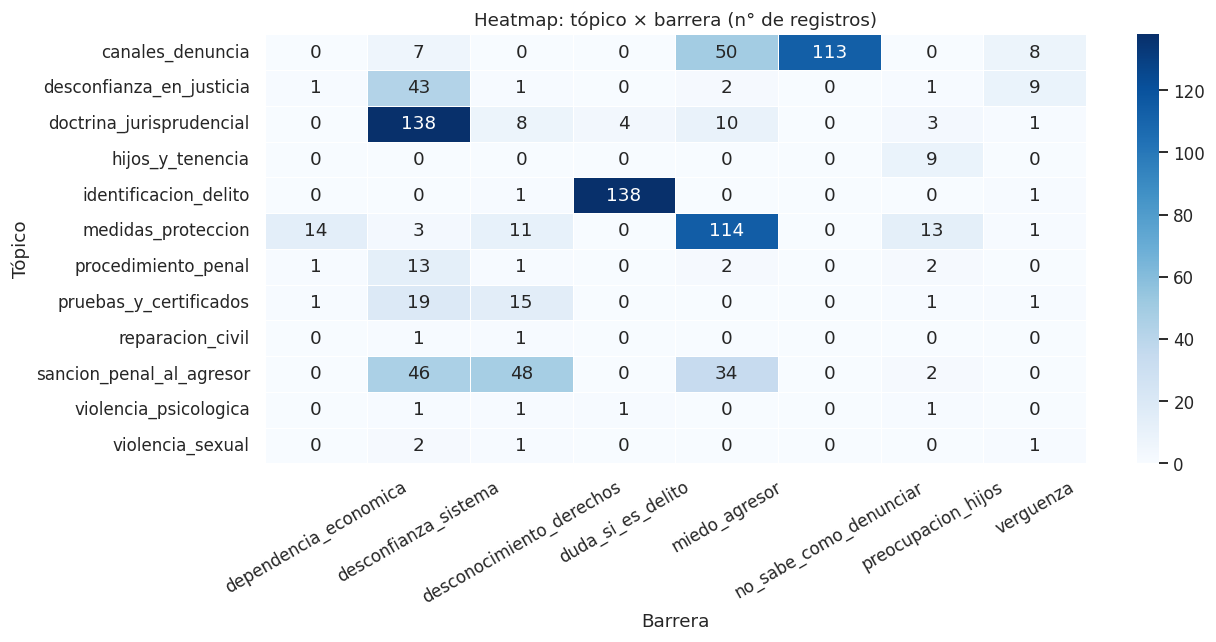

In [ ]:
pivot = pd.crosstab(df["topic"], df["barrier"])

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt="d", cmap="Blues", linewidths=0.5, ax=ax)
ax.set(title="Heatmap: tópico × barrera (n° de registros)",
       xlabel="Barrera", ylabel="Tópico")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 6. Dificultad de los negativos (BM25)

/tmp/ipykernel_8694/1650502705.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pos_scores, x="rank", y="score", ax=axes[1], palette="Reds_r")


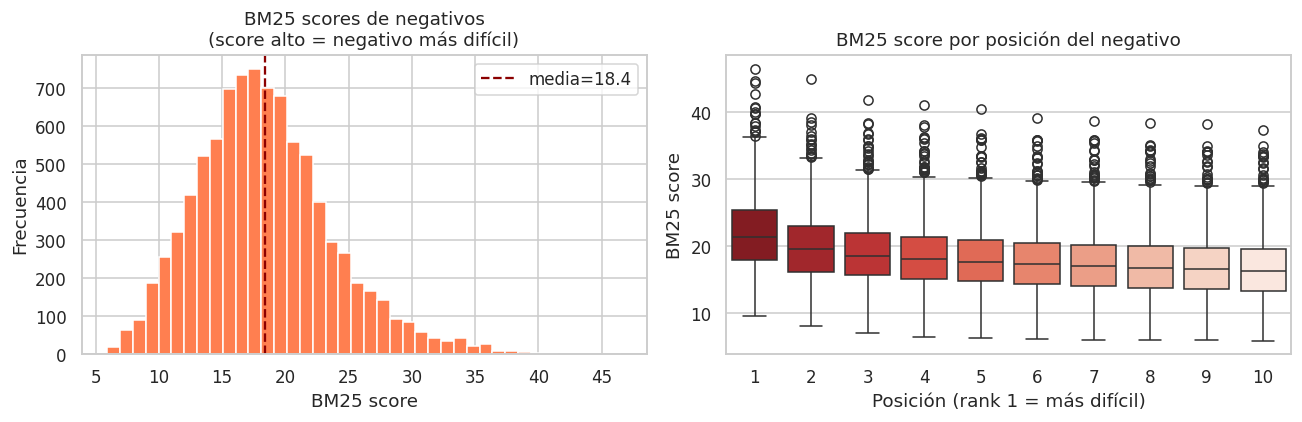

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribución de BM25 scores
df_scores["neg_bm25_scores"].hist(bins=40, edgecolor="white", ax=axes[0], color="coral")
axes[0].set(title="BM25 scores de negativos\n(score alto = negativo más difícil)",
            xlabel="BM25 score", ylabel="Frecuencia")
axes[0].axvline(df_scores["neg_bm25_scores"].mean(), color="darkred",
                linestyle="--", label=f"media={df_scores['neg_bm25_scores'].mean():.1f}")
axes[0].legend()

# BM25 score por posición del negativo (el 1° es el más difícil)
df_pos_idx = df.copy()
df_pos_idx["neg_bm25_scores"] = df_pos_idx["neg_bm25_scores"].apply(
    lambda x: x if isinstance(x, list) else [])
pos_scores = pd.DataFrame(
    [[i + 1, s] for scores in df_pos_idx["neg_bm25_scores"] for i, s in enumerate(scores)],
    columns=["rank", "score"]
)
sns.boxplot(data=pos_scores, x="rank", y="score", ax=axes[1], palette="Reds_r")
axes[1].set(title="BM25 score por posición del negativo",
            xlabel="Posición (rank 1 = más difícil)", ylabel="BM25 score")

plt.tight_layout()
plt.show()

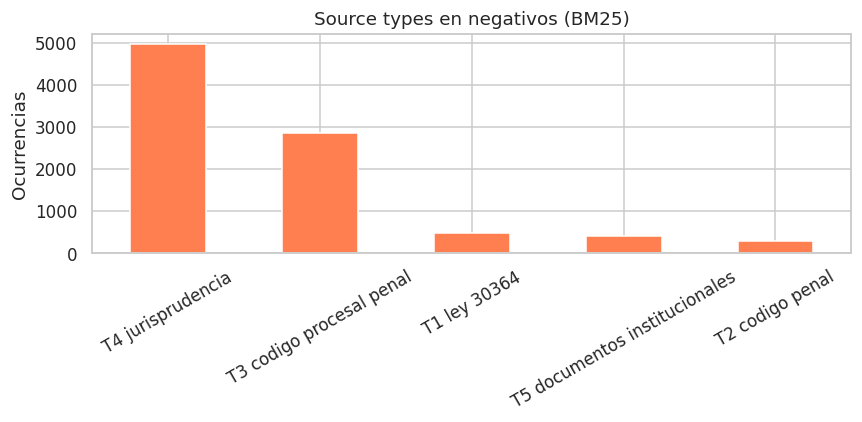

In [ ]:
# Source types de negativos
neg_src_counts = df_neg_src["negative_source_types"].value_counts()
neg_src_short = neg_src_counts.rename(index=lambda x: x.replace("tipo_0", "T").replace("_", " ") if isinstance(x, str) else x)

fig, ax = plt.subplots(figsize=(8, 4))
neg_src_short.plot(kind="bar", ax=ax, color="coral", edgecolor="white")
ax.set(title="Source types en negativos (BM25)", xlabel="", ylabel="Ocurrencias")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 7. Cobertura y registros problemáticos

In [ ]:
print(f"Registros con refs no resueltas (unresolved_count > 0): {(df['unresolved_count'] > 0).sum()}")
print(f"Registros sin jurisprudencia matcheada: {(~df['jurisprudence_matched']).sum()}")

# Mostrar los registros con más refs sin resolver
sin_resolver = df[df["unresolved_count"] > 0][
    ["case_id", "topic", "unresolved_count", "unresolved_positive_refs", "query"]
].sort_values("unresolved_count", ascending=False)

print(f"\nTop 10 con mayor unresolved_count:")
sin_resolver.head(10)

Registros con refs no resueltas (unresolved_count > 0): 38
Registros sin jurisprudencia matcheada: 28

Top 10 con mayor unresolved_count:


,case_id,topic,unresolved_count,unresolved_positive_refs,query
3,jp_00008_e0002,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a mi pareja si lo denuncio...
53,jp_00051_e0016,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a él si lo denuncio por to...
65,jp_00051_e0018,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a él si lo denuncio por to...
70,jp_00051_e0019,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...","¿Si lo denuncio, realmente le van a poner una ..."
76,jp_00051_e0020,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a él si lo denuncio por pe...
82,jp_00051_e0021,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a mi ex si lo denuncio por...
94,jp_00065_e0004,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...",¿Qué le puede pasar a él si lo denuncio por lo...
119,jp_00072_e0006,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...","¿Qué le puede pasar a él si lo denuncio, va a ..."
169,jp_00118_e0038,desconfianza_en_justicia,1,"[{'type': 'cpp', 'source_type': 'tipo_03_codig...",¿Y si los jueces dicen que no hay pruebas sufi...
203,jp_00122_e0005,sancion_penal_al_agresor,1,"[{'type': 'cp', 'source_type': 'tipo_02_codigo...","¿Si denuncio a mi ex por amenazarme, qué pena ..."


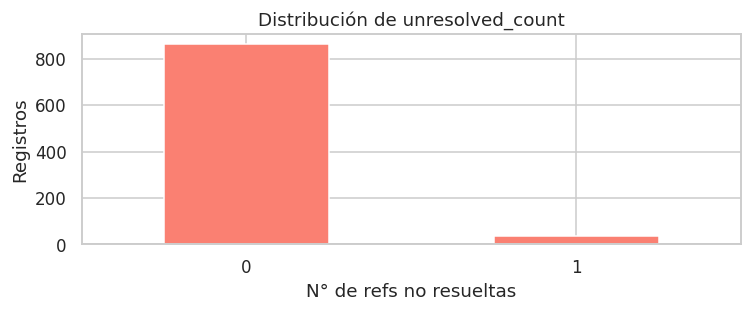

In [ ]:
# Distribución de unresolved_count
fig, ax = plt.subplots(figsize=(7, 3))
df["unresolved_count"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color="salmon", edgecolor="white")
ax.set(title="Distribución de unresolved_count", xlabel="N° de refs no resueltas", ylabel="Registros")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 8. Resumen para tesis

In [ ]:
resumen = {
    "Total registros": len(df),
    "Casos únicos": df["case_id"].nunique(),
    "Tópicos únicos": df["topic"].nunique(),
    "Barreras únicas": df["barrier"].nunique(),
    "Avg query_length (chars)": df["query_length"].mean().round(1),
    "Avg positivos por query": df["positive_context_count"].mean().round(2),
    "Negativos por query (fijo)": int(df["negative_count"].max()),
    "% con jurisprudencia como positivo": f"{df['has_jurisprudence_positive'].mean()*100:.1f}%",
    "% con protocolo institucional como positivo": f"{df['has_institutional_positive'].mean()*100:.1f}%",
    "Avg BM25 score negativos": df_scores["neg_bm25_scores"].mean().round(2),
    "Avg confidence LLM": df["confidence"].mean().round(3),
    "Registros con refs sin resolver": int((df["unresolved_count"] > 0).sum()),
    "Cobertura (% casos sin refs sin resolver)": f"{(df['unresolved_count']==0).mean()*100:.1f}%",
}

pd.Series(resumen, name="valor").to_frame()

,valor
Total registros,900
Casos únicos,178
Tópicos únicos,12
Barreras únicas,8
Avg query_length (chars),83.6
Avg positivos por query,1.45
Negativos por query (fijo),10
% con jurisprudencia como positivo,23.3%
% con protocolo institucional como positivo,20.7%
Avg BM25 score negativos,18.41
